In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

In [2]:
data=pd.read_csv('preprocessing.csv')

In [3]:
data.head()

,scholarship_received,placement_status,starting_salary_usd,gpa_or_score,test_score,origin_country_Finland,origin_country_Germany,origin_country_India,origin_country_Ireland,origin_country_Russia,...,visa_status_Schengen Student Visa,visa_status_Student Visa,visa_status_Study Permit,visa_status_Tier 4,post_graduation_visa_OPT,post_graduation_visa_PSW,post_graduation_visa_Post-Study Visa,post_graduation_visa_Work Permit,study_duration,Salary_Bin
0,0,1,0.242883,1.556464,0.679688,1,0,0,0,0,...,0,0,0,1,0,0,0,1,1.0,1
1,1,1,0.219806,-1.488781,0.765584,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0.0,1
2,1,1,0.365432,-0.658260,1.023273,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0.0,2
3,1,0,0.000000,-1.281151,0.336103,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0.0,1
4,1,0,0.000000,-0.589050,-1.210030,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0.5,1


In [4]:
data.shape

(4018, 172)

In [5]:
y = data["placement_status"]
X = data.drop("placement_status", axis=1)

In [6]:
# Define features, dropping leaky columns
X = data.drop(["starting_salary_usd", "Salary_Bin"], axis=1)
X = X.drop([col for col in X.columns if col.startswith('placement_')], axis=1)

In [7]:
correlations = pd.concat([X, y], axis=1).corr()['placement_status'].sort_values(ascending=False)
print(correlations.head(30))

placement_status                                            1.000000
field_of_study_Engineering                                  0.045214
destination_city_Vancouver                                  0.035881
destination_city_Birmingham                                 0.035158
destination_country_India                                   0.031925
university_name_Simon Fraser University                     0.027628
university_name_Higher School of Economics                  0.027493
destination_city_Pilani                                     0.026606
language_proficiency_test_IELTS                             0.025285
destination_city_Moscow                                     0.024658
destination_city_Galway                                     0.024257
destination_city_Kingston                                   0.024164
university_name_University of British Columbia              0.023073
destination_city_Mumbai                                     0.023073
destination_city_Manchester       

In [8]:
print(X.columns.tolist())

['scholarship_received', 'gpa_or_score', 'test_score', 'origin_country_Finland', 'origin_country_Germany', 'origin_country_India', 'origin_country_Ireland', 'origin_country_Russia', 'origin_country_South Africa', 'origin_country_United Arab Emirates', 'origin_country_United Kingdom', 'origin_country_United States', 'destination_country_Finland', 'destination_country_Germany', 'destination_country_India', 'destination_country_Ireland', 'destination_country_Russia', 'destination_country_South Africa', 'destination_country_United Arab Emirates', 'destination_country_United Kingdom', 'destination_country_United States', 'destination_city_Abu Dhabi', 'destination_city_Bangalore', 'destination_city_Berlin', 'destination_city_Birmingham', 'destination_city_Boston', 'destination_city_Cambridge', 'destination_city_Cape Town', 'destination_city_Chennai', 'destination_city_Chicago', 'destination_city_Cork', 'destination_city_Delhi', 'destination_city_Dubai', 'destination_city_Dublin', 'destinatio

In [9]:
# Apply PCA to retain 95% of the variance
pca = PCA(n_components=0.95)
data_pca = pca.fit_transform(X)

# Check how many components were kept
print("Original shape:", X.shape, y.shape)
print("Reduced shape:", data_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:", pca.explained_variance_ratio_.sum())

# Convert PCA result back to DataFrame
X_pca = pd.DataFrame(data_pca, columns=[f"PC{i+1}" for i in range(data_pca.shape[1])])

# (Optional) Combine with target y if needed
final_df = pd.concat([X_pca, y.reset_index(drop=True)], axis=1)

print(X_pca.head())

Original shape: (4018, 147) (4018,)
Reduced shape: (4018, 84)
Explained variance ratio: [0.1051526  0.10222717 0.02663651 0.02614604 0.02543495 0.02207555
 0.02146788 0.02127155 0.0204753  0.02028944 0.01984608 0.01820197
 0.01795211 0.01777467 0.01741657 0.01719066 0.01673716 0.01617449
 0.01563489 0.01472546 0.01443987 0.01385056 0.01334301 0.01330738
 0.01310186 0.01298656 0.0127805  0.01265761 0.01249175 0.01211105
 0.0105315  0.01042345 0.01020446 0.00983958 0.00968727 0.00951022
 0.00909573 0.00888779 0.00758314 0.00724223 0.00707334 0.00706795
 0.00696204 0.00689698 0.00685116 0.00673198 0.00670566 0.00667172
 0.00662835 0.00639113 0.00632999 0.00622101 0.00579559 0.00445425
 0.00431895 0.00413345 0.00410291 0.00394939 0.0035066  0.00347774
 0.00328067 0.00320138 0.00316807 0.0031545  0.00311636 0.00279828
 0.0026805  0.00207846 0.001964   0.00180411 0.00169256 0.0016851
 0.00167284 0.00165199 0.00163671 0.00162869 0.0016055  0.00156564
 0.00155304 0.00153769 0.00153448 0.001529

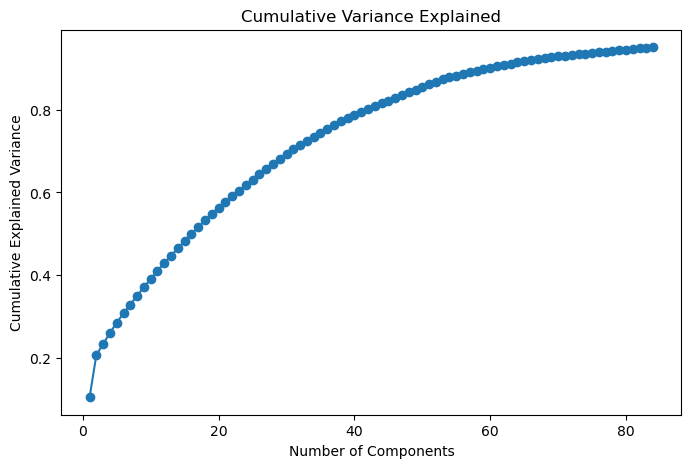

In [10]:
plt.figure(figsize=(8,5))
plt.plot(range(1, len(pca.explained_variance_ratio_)+1),
         pca.explained_variance_ratio_.cumsum(), marker='o')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Variance Explained")
plt.show()

In [27]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [12]:
X_model = X.copy() 
y_model =y.copy()

In [13]:
X_train, X_test, y_train, y_test = train_test_split( X_model, y_model, test_size=0.2, stratify=y_model, random_state=42)

In [22]:
#Logistic Regression
log_reg = LogisticRegression(max_iter=500)
log_reg.fit(X_train, y_train)

LogisticRegression(max_iter=500)

In [23]:
#GridSearchCV for Hyperparameter Tuning
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['liblinear', 'lbfgs'],
    'penalty': ['l2']
}

grid_lr = GridSearchCV(LogisticRegression(max_iter=1000), param_grid_lr, cv=5, scoring='accuracy')
grid_lr.fit(X_train, y_train)
print("Best Logistic Regression:", grid_lr.best_params_, "Accuracy:", grid_lr.best_score_)


Best Logistic Regression: {'C': 0.01, 'penalty': 'l2', 'solver': 'liblinear'} Accuracy: 0.5093307752309801


In [24]:
#RandomizedSearchCV for Hyperparameter Tuning
param_dist_lr = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs'],
    'penalty': ['l2']
}

rand_lr = RandomizedSearchCV(
    estimator=log_reg,
    param_distributions=param_dist_lr,
    n_iter=10,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)
rand_lr.fit(X_train, y_train)

print("Best Parameters (Logistic Regression):", rand_lr.best_params_)
print("Best CV Accuracy:", rand_lr.best_score_)

y_pred_lr = rand_lr.best_estimator_.predict(X_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred_lr))

Best Parameters (Logistic Regression): {'solver': 'liblinear', 'penalty': 'l2', 'C': 0.01}
Best CV Accuracy: 0.5093307752309801
Test Accuracy: 0.5099502487562189


In [26]:
#Compare GridSearchCV vs RandomizedSearchCV 
print("🔹 Logistic Regression Evaluation Comparison")
print("="*60)

#Best Models from GridSearchCV and RandomizedSearchCV
best_lr_grid = grid_lr.best_estimator_
best_lr_random = rand_lr.best_estimator_

#GridSearchCV Best Model 
y_pred_lr_grid = best_lr_grid.predict(X_test)
y_prob_lr_grid = best_lr_grid.predict_proba(X_test)[:, 1]

print("\nGridSearchCV Results:")
print("Accuracy :", accuracy_score(y_test, y_pred_lr_grid))
print("Precision:", precision_score(y_test, y_pred_lr_grid))
print("Recall   :", recall_score(y_test, y_pred_lr_grid))
print("F1 Score :", f1_score(y_test, y_pred_lr_grid))
print("AUC Score:", roc_auc_score(y_test, y_prob_lr_grid))

#RandomizedSearchCV Best Model
y_pred_lr_random = best_lr_random.predict(X_test)
y_prob_lr_random = best_lr_random.predict_proba(X_test)[:, 1]

print("\nRandomizedSearchCV Results:")
print("Accuracy :", accuracy_score(y_test, y_pred_lr_random))
print("Precision:", precision_score(y_test, y_pred_lr_random))
print("Recall   :", recall_score(y_test, y_pred_lr_random))
print("F1 Score :", f1_score(y_test, y_pred_lr_random))
print("AUC Score:", roc_auc_score(y_test, y_prob_lr_random))

🔹 Logistic Regression Evaluation Comparison

GridSearchCV Results:
Accuracy : 0.5099502487562189
Precision: 0.5111111111111111
Recall   : 0.5136476426799007
F1 Score : 0.5123762376237624
AUC Score: 0.5048173610638417

RandomizedSearchCV Results:
Accuracy : 0.5099502487562189
Precision: 0.5111111111111111
Recall   : 0.5136476426799007
F1 Score : 0.5123762376237624
AUC Score: 0.5048173610638417


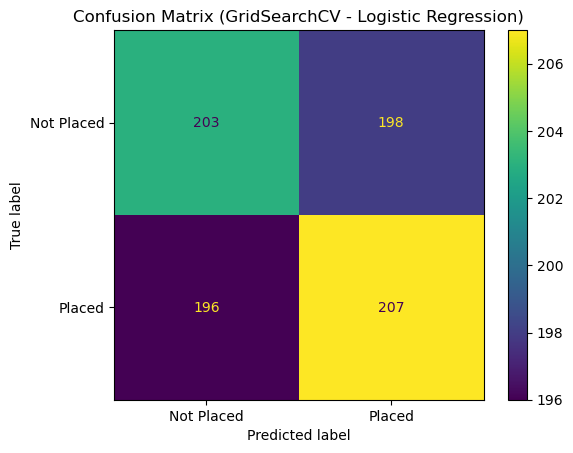

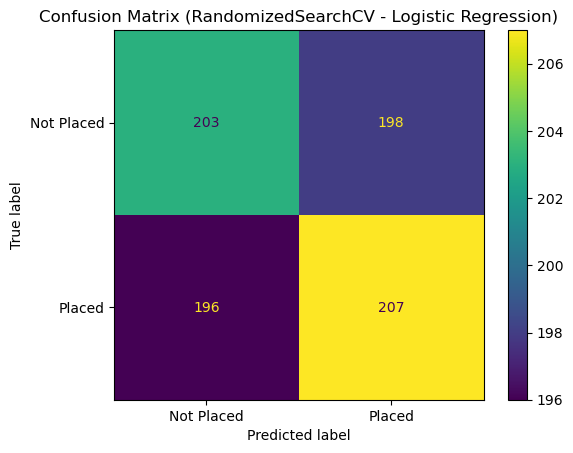

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Confusion Matrix for GridSearchCV Logistic Regression Model
cm_grid = confusion_matrix(y_test, y_pred_lr_grid)
disp_grid = ConfusionMatrixDisplay(confusion_matrix=cm_grid, display_labels=['Not Placed', 'Placed'])
disp_grid.plot()
plt.title('Confusion Matrix (GridSearchCV - Logistic Regression)')
plt.show()

# Confusion Matrix for RandomizedSearchCV Logistic Regression Model
cm_random = confusion_matrix(y_test, y_pred_lr_random)
disp_random = ConfusionMatrixDisplay(confusion_matrix=cm_random, display_labels=['Not Placed', 'Placed'])
disp_random.plot()
plt.title('Confusion Matrix (RandomizedSearchCV - Logistic Regression)')
plt.show()